# **Identify Problem**

### **Tujuan & Latar Belakang:**

Analisis pricing pada produk pakaian dilakukan untuk memahami bagaimana atribut produk mempengaruhi harga serta mengetahui faktor yang paling berkontribusi terhadap pembentukan price.

**Pendekatan Hedonic Pricing digunakan untuk:**

*   memahami hubungan atribut produk
terhadap harga
*   mengetahui fitur yang paling berpengaruh
*   membantu analisis strategi pricing
*   mengidentifikasi pola harga berdasarkan karakteristik produk

In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# **Data Collection**

In [ ]:
import kagglehub

# Download dataset dari Kaggle
path = kagglehub.dataset_download("mrsimple07/clothes-price-prediction")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'clothes-price-prediction' dataset.
Path to dataset files: /kaggle/input/clothes-price-prediction


In [ ]:
import os

os.listdir('/kaggle/input/clothes-price-prediction')

['clothes_price_prediction_data.csv']

In [ ]:
df = pd.read_csv('/kaggle/input/clothes-price-prediction/clothes_price_prediction_data.csv')
df.head()

,Brand,Category,Color,Size,Material,Price
0,New Balance,Dress,White,XS,Nylon,182
1,New Balance,Jeans,Black,XS,Silk,57
2,Under Armour,Dress,Red,M,Wool,127
3,Nike,Shoes,Green,M,Cotton,77
4,Adidas,Sweater,White,M,Nylon,113


Dataset yang digunakan merupakan dataset produk pakaian yang terdiri dari beberapa atribut kategorikal dan satu atribut numerik sebagai target.

Atribut pada dataset terdiri dari:

- Brand → merek pakaian
- Category → jenis pakaian
- Color → warna pakaian
- Size → ukuran pakaian
- Material → bahan pakaian
- Price → harga produk

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Brand     1000 non-null   object
 1   Category  1000 non-null   object
 2   Color     1000 non-null   object
 3   Size      1000 non-null   object
 4   Material  1000 non-null   object
 5   Price     1000 non-null   int64 
dtypes: int64(1), object(5)
memory usage: 47.0+ KB


In [ ]:
df.describe()

,Price
count,1000.000000
mean,106.289000
std,53.695444
min,10.000000
25%,59.750000
50%,108.000000
75%,150.000000
max,199.000000


# **Exploratory Data Analysis (EDA)**

### **Analisis Rata-Rata Harga Berdasarkan Brand**

In [ ]:
df.groupby('Brand')['Price'].mean()

,Price
Brand,
Adidas,104.054217
New Balance,115.457317
Nike,101.909091
Puma,106.136905
Reebok,106.493671
Under Armour,103.960894


Berdasarkan hasil analisis rata-rata harga per brand, terlihat bahwa seluruh brand memiliki rata-rata harga yang relatif mirip, yaitu berada pada rentang sekitar 101 hingga 115.

New Balance memiliki rata-rata harga tertinggi, sedangkan Nike memiliki rata-rata harga terendah. Namun selisih antar brand tidak terlalu besar.

Hal ini menunjukkan bahwa atribut Brand belum memberikan pengaruh yang kuat terhadap pembentukan harga produk pada dataset yang digunakan.

### **Analisis Variasi Harga Berdasarkan Brand**

In [ ]:
brand_analysis = df.pivot_table(
    index='Brand',
    values='Price',
    aggfunc=['max', 'min', 'mean']
)

print(brand_analysis)

               max   min        mean
             Price Price       Price
Brand                               
Adidas         198    10  104.054217
New Balance    198    14  115.457317
Nike           199    11  101.909091
Puma           199    10  106.136905
Reebok         198    10  106.493671
Under Armour   198    10  103.960894


Berdasarkan hasil analisis nilai minimum, maksimum, dan rata-rata harga pada setiap brand, terlihat bahwa seluruh brand memiliki rentang harga yang sangat besar.

Sebagai contoh, brand Nike memiliki harga minimum sebesar 11 dan harga maksimum sebesar 199, meskipun rata-rata harganya berada di sekitar 101.

Hal serupa juga terjadi pada brand lainnya, di mana perbedaan antara harga minimum dan maksimum sangat jauh. Kondisi ini menunjukkan bahwa harga produk sangat bervariasi meskipun berada dalam brand yang sama.

Variasi harga yang tinggi ini menunjukkan bahwa atribut Brand saja belum cukup untuk menjelaskan pembentukan harga secara konsisten.

### **rata-rata harga per kategori**

In [ ]:
category_price = df.groupby('Category')['Price'].mean().sort_values(ascending=False)

print(category_price)

Category
Dress      114.506024
Shoes      108.569767
Sweater    106.781250
T-shirt    104.562500
Jacket     102.827225
Jeans      100.748503
Name: Price, dtype: float64


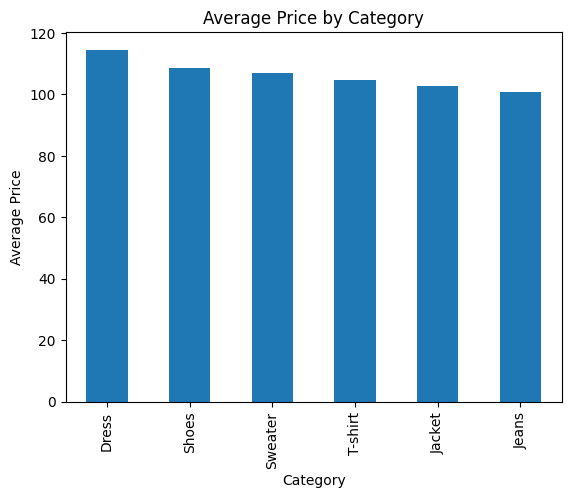

In [ ]:
import matplotlib.pyplot as plt

category_price.plot(kind='bar')

plt.title('Average Price by Category')
plt.ylabel('Average Price')
plt.xlabel('Category')
plt.show()

Hasil analisis menunjukkan bahwa kategori produk memiliki perbedaan rata-rata harga. Kategori Dress memiliki rata-rata harga tertinggi, sedangkan Jeans memiliki rata-rata harga terendah.

Hal ini menunjukkan bahwa category memiliki pengaruh terhadap pembentukan harga produk, meskipun pengaruhnya tidak terlalu besar.

### **rata-rata harga per material**

In [ ]:
material_price = df.groupby('Material')['Price'].mean().sort_values(ascending=False)

print(material_price)

Material
Nylon        109.387097
Wool         109.197674
Denim        107.687117
Polyester    106.434286
Cotton       103.345679
Silk         101.913295
Name: Price, dtype: float64


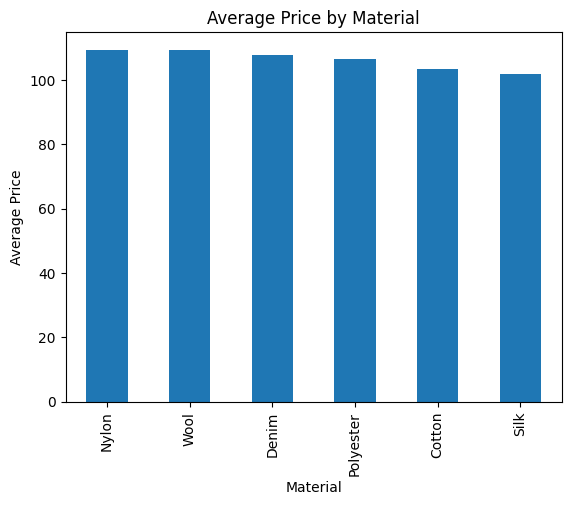

In [ ]:
material_price.plot(kind='bar')

plt.title('Average Price by Material')
plt.ylabel('Average Price')
plt.xlabel('Material')
plt.show()

Material produk menunjukkan pengaruh terhadap harga. Material seperti Nylon dan Wool memiliki rata-rata harga yang lebih tinggi dibanding material lainnya.

Namun perbedaan harga antar material masih relatif kecil sehingga hubungan antara material dan harga belum terlalu kuat.

### **rata-rata harga persize**

In [ ]:
# rata-rata harga persize
size_price = df.groupby('Size')['Price'].mean().sort_values(ascending=False)

print(size_price)

Size
XS     110.117347
XXL    109.341040
L      106.156028
M      105.191083
S      103.903614
XL     102.149701
Name: Price, dtype: float64


Berdasarkan hasil analisis, rata-rata harga pada setiap ukuran tidak memiliki perbedaan yang terlalu besar. Size XS memiliki rata-rata harga tertinggi, sedangkan XL memiliki rata-rata harga terendah.

Hal ini menunjukkan bahwa atribut Size tidak memberikan pengaruh yang signifikan terhadap harga produk.

In [ ]:
color_price = df.groupby('Color')['Price'].mean().sort_values(ascending=False)

print(color_price)

Color
White     113.690058
Blue      107.061350
Red       106.142857
Yellow    104.236994
Green     103.518519
Black     102.834356
Name: Price, dtype: float64


### **Kombinasi Atribut**

In [ ]:
# brand dan material dan color
combo_price3 = df.groupby(
    ['Brand', 'Material', 'Color']
)['Price'].mean().sort_values(ascending=False)

print(combo_price3.head(20))

Brand         Material   Color 
New Balance   Denim      White     197.000000
Adidas        Denim      Green     181.500000
Under Armour  Denim      White     175.000000
New Balance   Polyester  Blue      169.500000
Nike          Denim      Blue      166.200000
Reebok        Wool       Yellow    164.000000
New Balance   Cotton     Black     162.500000
Under Armour  Nylon      Blue      153.000000
New Balance   Nylon      White     150.500000
Reebok        Polyester  White     149.500000
Puma          Cotton     Red       149.250000
New Balance   Wool       Blue      148.333333
Under Armour  Silk       White     148.250000
New Balance   Polyester  Red       147.000000
              Wool       Green     147.000000
Adidas        Wool       White     147.000000
Puma          Denim      White     145.500000
Under Armour  Cotton     Green     145.000000
Adidas        Polyester  Yellow    145.000000
                         Green     144.750000
Name: Price, dtype: float64


In [ ]:
# brand dan material
combo_price = df.groupby(
    ['Brand', 'Material']
)['Price'].mean().sort_values(ascending=False)

print(combo_price.head(40))

Brand         Material 
New Balance   Nylon        124.772727
              Cotton       122.833333
Under Armour  Denim        122.615385
New Balance   Wool         119.571429
Puma          Wool         115.620690
Adidas        Polyester    115.468750
Puma          Nylon        115.192308
Reebok        Silk         111.000000
New Balance   Polyester    111.000000
Adidas        Nylon        110.870968
Nike          Silk         110.379310
Reebok        Denim        110.341463
Nike          Wool         109.791667
Reebok        Cotton       109.041667
Under Armour  Nylon        108.321429
Puma          Cotton       108.148148
              Polyester    106.969697
New Balance   Silk         106.931034
Nike          Denim        106.772727
New Balance   Denim        106.640000
Reebok        Wool         106.095238
              Polyester    105.518519
Nike          Nylon        104.466667
Under Armour  Cotton       102.571429
Adidas        Wool         102.100000
Under Armour  Wool        

In [ ]:
# categori dan material
combo2 = df.groupby(
    ['Category', 'Material']
)['Price'].mean().sort_values(ascending=False)

print(combo2.head(40))

Category  Material 
Sweater   Denim        125.944444
Shoes     Nylon        124.484848
Dress     Polyester    124.000000
Jacket    Wool         122.318182
Shoes     Silk         120.333333
Dress     Wool         118.250000
T-shirt   Cotton       115.791667
          Wool         115.421053
Dress     Nylon        114.730769
Jeans     Cotton       112.000000
Dress     Silk         111.777778
Sweater   Polyester    110.200000
T-shirt   Silk         107.758621
Dress     Cotton       107.590909
          Denim        107.344828
Jacket    Nylon        106.535714
          Denim        105.923077
Shoes     Polyester    105.038462
Jeans     Denim        104.375000
          Polyester    104.216216
Sweater   Nylon        102.941176
Jeans     Nylon        102.333333
Shoes     Wool         101.806452
Sweater   Silk         100.416667
Shoes     Denim        100.208333
T-shirt   Polyester     99.241379
          Nylon         99.074074
Sweater   Cotton        98.914286
Shoes     Cotton        97.5

Analisis kombinasi atribut menunjukkan bahwa kombinasi fitur memberikan pola harga yang lebih jelas dibanding fitur tunggal.

Kombinasi seperti:
- Category + Material
- Brand + Material

menunjukkan variasi harga yang lebih besar dibanding hanya menggunakan satu atribut saja.

### **Temuan Utama Dataset**

In [ ]:
combo_analysis = df.groupby(
    ['Brand', 'Category', 'Material']
)['Price'].agg(['min', 'max', 'mean', 'count'])

combo_analysis.sort_values(by='max', ascending=False).head(20)

min  max        mean  count
Brand        Category Material                              
Nike         Jeans    Cotton     179  199  189.000000      2
Puma         Jacket   Cotton      23  199  134.800000      5
             Dress    Polyester   44  199  119.200000     10
Adidas       Jacket   Denim       51  198  113.000000      4
New Balance  Shoes    Wool        14  198   85.375000      8
Puma         Jacket   Wool        14  198  125.555556      9
New Balance  Dress    Wool       107  198  153.200000      5
Adidas       Jacket   Nylon       38  198  136.333333      3
Reebok       Jeans    Polyester  137  198  158.000000      3
Under Armour Shoes    Silk        10  198  125.500000      6
Nike         Sweater  Polyester   38  197  116.500000      6
New Balance  Sweater  Denim       31  197  126.000000      6
Puma         Shoes    Nylon       35  196  139.818182     11
Nike         Sweater  Denim       99  196  153.250000      4
Under Armour Jacket   Silk        12  196   75.000000      8
Reebok       T-shirt  Wool        13  196   99.500000      4
New Balance  T-shirt  Cotton      90  196  147.000000      5
Reebok       Dress    Silk        23  196  103.000000      8
Under Armour Dress    Silk       135  195  161.000000      4
             Shoes    Nylon       76  195  137.750000      4

In [ ]:
df[
    (df['Category'] == 'Jacket') &
    (df['Material'] == 'Wool') &
    (df['Brand'] == 'Nike')
]

,Brand,Category,Color,Size,Material,Price
596,Nike,Jacket,Black,L,Wool,124
646,Nike,Jacket,Green,XXL,Wool,183
748,Nike,Jacket,Green,XXL,Wool,127
830,Nike,Jacket,Green,XS,Wool,159
879,Nike,Jacket,Green,L,Wool,122


Ditemukan beberapa data dengan atribut yang identik namun memiliki harga yang sangat berbeda.

Sebagai contoh:
produk dengan Brand Nike, Category Jacket, Color Green, Size XXL, dan Material Wool memiliki harga 127 dan 183.

Hal ini menunjukkan adanya inkonsistensi hubungan antara atribut dan harga sehingga model mengalami kesulitan dalam mempelajari pola pricing secara konsisten.

# **Data Preprocessing**

### **Data Cleaning**
Data dibersihkan dari duplikasi dan dicek missing value untuk memastikan kualitas data.

In [ ]:
# pengecekan missing value
df.isnull().sum()

,0
Brand,0
Category,0
Color,0
Size,0
Material,0
Price,0


In [ ]:
# pengecekan duplikasi data
df.duplicated().sum()

np.int64(0)

### **Feature Selection**

In [ ]:
# pemisahan feature dan target
X = df[['Brand', 'Category', 'Material']]
y = df['Price']

Dilakukan feature selection dengan memilih atribut yang dianggap lebih relevan terhadap harga, yaitu:

- Brand
- Category
- Material

Penghapusan fitur seperti Color dan Size menghasilkan sedikit peningkatan performa model, yang menunjukkan bahwa fitur tersebut memiliki pengaruh yang relatif kecil terhadap price.

### **One Hot Encoding**

In [ ]:
# encoding data kategorikal menggunakan One Hot Encoding
categorical_features = [
    'Brand',
    'Category',
    'Material'
]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(drop='first'), categorical_features)
    ]
)

### **Train-Test Split**

In [ ]:
# pembagian data train dan test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# **Modeling Hedonic Regression**

In [ ]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [ ]:
encoded_columns = preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_features)

print(encoded_columns)

['Brand_New Balance' 'Brand_Nike' 'Brand_Puma' 'Brand_Reebok'
 'Brand_Under Armour' 'Category_Jacket' 'Category_Jeans' 'Category_Shoes'
 'Category_Sweater' 'Category_T-shirt' 'Material_Denim' 'Material_Nylon'
 'Material_Polyester' 'Material_Silk' 'Material_Wool']


In [ ]:
X_train_df = pd.DataFrame(
    X_train_processed.toarray(),
    columns=encoded_columns
)

X_train_df.head()

,Brand_New Balance,Brand_Nike,Brand_Puma,Brand_Reebok,Brand_Under Armour,Category_Jacket,Category_Jeans,Category_Shoes,Category_Sweater,Category_T-shirt,Material_Denim,Material_Nylon,Material_Polyester,Material_Silk,Material_Wool
0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
3,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0


In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train_processed, y_train)

LinearRegression()

In [ ]:
y_pred = model.predict(X_test_processed)

# **Hasil Evaluasi Model**

In [ ]:
from sklearn.metrics import mean_absolute_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("R2:", r2)

MAE: 45.8462783083936
R2: 0.01714971152751188


Hasil evaluasi model menunjukkan:

- MAE sebesar sekitar 45
- R² mendekati 0

Nilai R² yang rendah menunjukkan bahwa atribut pada dataset belum mampu menjelaskan variasi harga dengan baik.

Hal ini menunjukkan bahwa hubungan antara atribut produk dan harga masih lemah.

# **Analisis Coefficient Regresi**

In [ ]:
coef_df = pd.DataFrame({
    'Feature': encoded_columns,
    'Coefficient': model.coef_
})

print(coef_df.sort_values(by='Coefficient', ascending=False))

               Feature  Coefficient
0    Brand_New Balance     7.866516
14       Material_Wool     6.710011
10      Material_Denim     6.032352
11      Material_Nylon     5.755075
12  Material_Polyester     2.670296
3         Brand_Reebok     1.364868
4   Brand_Under Armour     1.235964
7       Category_Shoes     0.189957
2           Brand_Puma    -0.813575
13       Material_Silk    -1.741399
1           Brand_Nike    -2.211829
9     Category_T-shirt    -3.634771
8     Category_Sweater    -6.778899
5      Category_Jacket    -7.495602
6       Category_Jeans    -8.024273


Koefisien regresi digunakan untuk melihat pengaruh masing-masing atribut terhadap harga.

Hasil analisis menunjukkan bahwa:
- Material Wool memberikan pengaruh positif terhadap harga
- Brand New Balance cenderung meningkatkan harga
- Category Jeans memberikan pengaruh negatif terhadap harga

Namun interpretasi koefisien dilakukan secara hati-hati karena performa model secara keseluruhan masih rendah.